# TP n° 2 — XGBoost : prédire la survie des passagers du Titanic et régler un modèle de boosting

**Module Machine Learning** · Compte rendu (notebook commenté + réponses Q1 à Q35)

**Exécution.** Le notebook s'exécute de bout en bout (*Run All*) avec le fichier `titanic3.csv` placé dans le même dossier. Graine fixée (`SEED = 42`) ; versions : Python 3.13, xgboost 3.4.1, scikit-learn. Les figures sont enregistrées dans `figures/`.

**Données.** Titanic, 1 309 passagers × 14 colonnes (même structure que OpenML n° 40945). Je n'ai pas pu télécharger le CSV depuis OpenML depuis mon environnement ; j'ai utilisé une copie GitHub du fichier *titanic3* (dépôt `gausshuang/datas`, `sets/titanic3.csv`), dont j'ai vérifié les dimensions (1 309 × 14), les noms de colonnes et le taux de survie (38,2 %). Les valeurs manquantes y sont vides au lieu de « ? » : le code lit les deux (`na_values=["?", ""]`). Si votre CSV OpenML diffère légèrement, remplacez simplement le fichier et relancez : les chiffres rédigés ci-dessous sont ceux de cette exécution.

**Protocole.** Choix des hyperparamètres : uniquement par validation croisée stratifiée à 5 plis sur l'ensemble d'entraînement. Le jeu de test n'intervient que pour évaluer le modèle initial (Q15–Q23, rien n'est choisi) et, une seule fois, le modèle optimisé (partie 9).

In [4]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest, spearmanr
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score, GridSearchCV)
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import xgboost
from xgboost import XGBClassifier
try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")
SEED = 42                       # graine unique pour tout le notebook
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)
pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("xgboost", xgboost.__version__)

ModuleNotFoundError: No module named 'numpy'

## Partie 1 — Compréhension du problème et des données

In [ ]:
# Les valeurs manquantes sont "?" dans le CSV OpenML ; la copie utilisée ici les laisse vides : on gère les deux.
df = pd.read_csv("titanic3.csv", na_values=["?", ""])
print("Dimensions :", df.shape)
print("Observations :", df.shape[0], "| Variables :", df.shape[1], "(dont la cible)")
display(df.dtypes.to_frame("type").T)
vc = df["survived"].value_counts().sort_index()
print("\nEffectifs  0 (décès) / 1 (survie) :", vc.to_dict())
print(f"Proportion de survivants : {df['survived'].mean():.4f}")
print(f"Accuracy d'un modèle qui prédit toujours 'n'a pas survécu' : {1 - df['survived'].mean():.4f}")

Dimensions : (1309, 14)
Observations : 1309 | Variables : 14 (dont la cible)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
type,int64,int64,str,str,float64,int64,int64,str,float64,str,str,str,float64,str



Effectifs  0 (décès) / 1 (survie) : {0: 809, 1: 500}
Proportion de survivants : 0.3820
Accuracy d'un modèle qui prédit toujours 'n'a pas survécu' : 0.6180


### Réponses — Partie 1

**Q1.** L'objectif est de prédire si un passager a survécu au naufrage à partir de caractéristiques connues avant le départ (classe, sexe, âge, famille à bord, tarif, port d'embarquement). La variable cible est `survived` (1 = survie, 0 = décès). C'est une **classification** (binaire) car la cible est une catégorie à deux modalités et non une quantité continue : on prédit une classe, ainsi que la probabilité de cette classe.

**Q2.** 1 309 observations et 14 variables (la cible + 13 variables potentiellement explicatives). 500 survivants (**38,2 %**) et 809 décès (61,8 %) : classes modérément déséquilibrées (environ 1 survivant pour 1,6 décès), sans déséquilibre extrême. Un modèle qui prédirait toujours « n'a pas survécu » aurait une accuracy de **61,8 %**.

**Q3.** Hypothèses formulées avant l'analyse : **(H1)** « les femmes et les enfants d'abord » : le sexe féminin et un jeune âge augmentent la survie ; **(H2)** les passagers de première classe, mieux placés et plus proches des canots, survivent davantage que ceux de troisième classe. Elles sont vérifiées en Q5 et Q22.

## Partie 2 — Exploration et préparation

,n_manquants,taux_%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1
embarked,2,0.2
fare,1,0.1
sibsp,0,0.0
name,0,0.0
survived,0,0.0


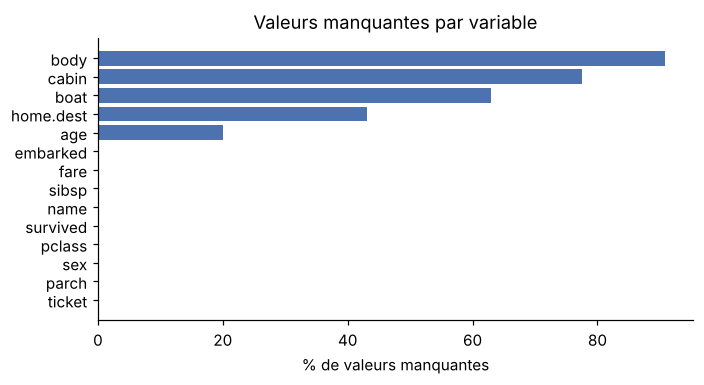

In [ ]:
miss = df.isna().mean().sort_values(ascending=False)
miss_tab = pd.DataFrame({"n_manquants": df.isna().sum()[miss.index], "taux_%": (100 * miss).round(1)})
display(miss_tab)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(miss.index[::-1], 100 * miss.values[::-1], color="#4C72B0")
ax.set_xlabel("% de valeurs manquantes"); ax.set_title("Valeurs manquantes par variable")
plt.tight_layout(); plt.savefig("figures/q4_valeurs_manquantes.png"); plt.show()


--- sex ---


,taux_survie_%,effectif
sex,,
female,72.7,466
male,19.1,843



--- pclass ---


,taux_survie_%,effectif
pclass,,
1,61.9,323
2,43.0,277
3,25.5,709



--- age_classe ---


,taux_survie_%,effectif
age_classe,,
0-12,57.4,94
13-18,41.4,99
19-30,36.8,416
31-50,41.2,342
51+,40.0,95


... (2 outputs left out)


--- age manquant ? ---


,taux_survie_%,effectif
age_manquant,,
False,40.8,1046
True,27.8,263



--- sexe x classe (taux de survie %) ---


pclass,1,2,3
sex,,,
female,96.5,88.7,49.1
male,34.1,14.6,15.2


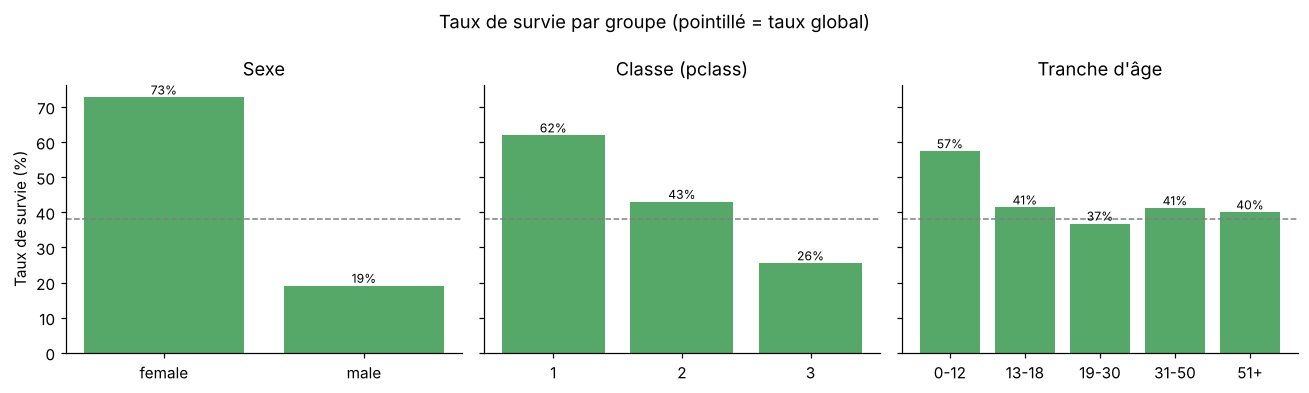

In [ ]:
df["age_classe"] = pd.cut(df["age"], [0, 12, 18, 30, 50, 100],
                          labels=["0-12", "13-18", "19-30", "31-50", "51+"])
def taux(col):
    g = df.groupby(col, observed=True)["survived"].agg(["mean", "count"])
    g["mean"] = (100 * g["mean"]).round(1)
    return g.rename(columns={"mean": "taux_survie_%", "count": "effectif"})
for col in ["sex", "pclass", "age_classe", "embarked"]:
    print(f"\n--- {col} ---"); display(taux(col))
print("\n--- age manquant ? ---")
display(taux(df["age"].isna().rename("age_manquant")))
print("\n--- sexe x classe (taux de survie %) ---")
display((100 * df.pivot_table(index="sex", columns="pclass", values="survived")).round(1))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, col, title in zip(axes, ["sex", "pclass", "age_classe"], ["Sexe", "Classe (pclass)", "Tranche d'âge"]):
    t = taux(col)
    bars = ax.bar(t.index.astype(str), t["taux_survie_%"], color="#55A868")
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8); ax.set_title(title)
    ax.axhline(100 * df["survived"].mean(), ls="--", c="grey", lw=1)
axes[0].set_ylabel("Taux de survie (%)")
fig.suptitle("Taux de survie par groupe (pointillé = taux global)")
plt.tight_layout(); plt.savefig("figures/q5_taux_survie.png"); plt.show()

In [ ]:
# Q6-Q8 : préparation des variables explicatives
def prepare(d):
    X = pd.DataFrame(index=d.index)
    X["pclass"] = d["pclass"]                              # ordinale : 1 < 2 < 3, gardée numérique
    X["sex_female"] = (d["sex"] == "female").astype(int)   # binaire
    X["age"] = d["age"]                                    # NaN laissés à XGBoost
    X["sibsp"] = d["sibsp"]; X["parch"] = d["parch"]
    X["fare"] = d["fare"]
    for p in ["C", "Q", "S"]:                              # one-hot du port d'embarquement
        X[f"embarked_{p}"] = (d["embarked"] == p).astype(int)
    return X

X = prepare(df)
y = df["survived"].astype(int)
print("Variables conservées :", list(X.columns))
print("Variables écartées   : name, ticket, cabin, home.dest (texte) + boat, body (fuite) + survived (cible)")
display(X.head())
print("Valeurs manquantes restantes dans X :", X.isna().sum()[X.isna().sum() > 0].to_dict())

Variables conservées : ['pclass', 'sex_female', 'age', 'sibsp', 'parch', 'fare', 'embarked_C', 'embarked_Q', 'embarked_S']
Variables écartées   : name, ticket, cabin, home.dest (texte) + boat, body (fuite) + survived (cible)


,pclass,sex_female,age,sibsp,parch,fare,embarked_C,embarked_Q,embarked_S
0,1,1,29.00,0,0,211.3375,0,0,1
1,1,0,0.92,1,2,151.5500,0,0,1
2,1,1,2.00,1,2,151.5500,0,0,1
3,1,0,30.00,1,2,151.5500,0,0,1
4,1,1,25.00,1,2,151.5500,0,0,1


Valeurs manquantes restantes dans X : {'age': 263, 'fare': 1}


In [ ]:
# Q9 : boat et body
print("Survie selon présence d'un numéro de canot (boat) :")
display(df.groupby(df["boat"].notna().rename("boat_renseigné"))["survived"].agg(["mean", "count"]).round(3))
print("Survie selon présence d'un numéro de corps (body) :")
display(df.groupby(df["body"].notna().rename("body_renseigné"))["survived"].agg(["mean", "count"]).round(3))
print("Survivants sans canot renseigné :", int(((df.survived == 1) & df.boat.isna()).sum()),
      "| non-survivants avec canot :", int(((df.survived == 0) & df.boat.notna()).sum()),
      "| survivants avec numéro de corps :", int(((df.survived == 1) & df.body.notna()).sum()))

Survie selon présence d'un numéro de canot (boat) :


,mean,count
boat_renseigné,,
False,0.028,823
True,0.981,486


Survie selon présence d'un numéro de corps (body) :


,mean,count
body_renseigné,,
False,0.421,1188
True,0.000,121


Survivants sans canot renseigné : 23 | non-survivants avec canot : 9 | survivants avec numéro de corps : 0


### Réponses — Partie 2

**Q4. Valeurs manquantes.**

| Variable | Manquants | Taux |
|---|---|---|
| `body` | 1 188 | 90,8 % |
| `cabin` | 1 014 | 77,5 % |
| `boat` | 823 | 62,9 % |
| `home.dest` | 564 | 43,1 % |
| `age` | 263 | 20,1 % |
| `embarked` | 2 | 0,2 % |
| `fare` | 1 | 0,1 % |

Les autres colonnes sont complètes. `body` et `cabin` sont trop lacunaires pour être exploitables (`home.dest` et `boat` aussi, pour d'autres raisons). Pour `boat` et `body`, « manquant » signifie « sans objet » (pas de canot, corps non retrouvé) : ce n'est pas du hasard, voir Q9. `age` (20 %) est utilisable.

**Q5. Taux de survie par groupe** (figure `figures/q5_taux_survie.png`).

- Sexe : femmes **72,7 %** contre hommes **19,1 %**.
- Classe : 1re **61,9 %**, 2e 43,0 %, 3e **25,5 %**.
- Âge : 0–12 ans **57,4 %** ; 13–18 : 41,4 % ; 19–30 : 36,8 % ; 31–50 : 41,2 % ; 51+ : 40,0 %.
- Croisement sexe × classe : femmes de 1re classe 96,5 %, femmes de 3e classe 49,1 %, hommes de 3e classe 15,2 %.

Les hypothèses sont **confirmées**, avec une nuance : sexe et classe pèsent fortement, alors que l'âge ne joue nettement que pour les enfants de moins de 12 ans (au-delà, les taux sont proches de 37–41 %). On note aussi que les passagers sans âge renseigné survivent moins (27,8 % contre 40,8 %) et que le port de Cherbourg affiche 55,6 % de survie contre 33,3 % pour Southampton.

**Q6. Encodage des variables catégorielles.** Les variables catégorielles sont `sex`, `embarked` (nominales) et `pclass` (ordinale), plus les variables textuelles écartées en Q8.
- `sex` → une colonne binaire `sex_female` (0/1) : deux modalités, une seule colonne suffit.
- `embarked` → **one-hot** (`embarked_C/Q/S`) : les ports n'ont pas d'ordre naturel ; coder 0/1/2 imposerait un ordre artificiel. Les 2 valeurs manquantes donnent trois zéros.
- `pclass` → entier 1/2/3 conservé tel quel : l'ordre est réel et les arbres coupent par seuil (« pclass ≤ 1,5 »), un one-hot serait superflu.

**Q7. Valeurs manquantes de `age`.** Choix retenu : **laisser les NaN à XGBoost**, qui apprend à chaque coupure la direction à suivre pour les valeurs manquantes.
- Avantages : aucune valeur inventée, aucune statistique à calculer (donc aucun risque de fuite via l'imputation) et l'information « âge absent » est conservée, ce qui compte ici car elle est liée à la survie (27,8 % contre 40,8 %).
- Risques : comportement moins transparent ; le modèle suppose que le mécanisme de non-réponse restera le même sur de nouvelles données.
- Alternative (imputation par la médiane) : fabrique un âge identique pour 20 % des passagers et écrase la variance ; la médiane doit être calculée sur l'entraînement seul, sinon il y a fuite. Pour comparer, j'ai testé trois stratégies en validation croisée sur le train : NaN laissés = 0,7832 ; médiane = 0,7841 ; médiane + indicateur = 0,7851. Ces écarts (≤ 0,2 point) sont très inférieurs à l'écart-type entre plis (1,3 à 2,2 points) : aucune stratégie n'est meilleure de façon détectable, d'où le choix de la plus simple. Le seul `fare` manquant est traité de la même façon.

**Q8. Variables textuelles écartées.**
- `name` : identifiant quasi unique ; seul le titre (Mr, Miss, Master…) porterait du signal, déjà largement contenu dans `sex` et `age`, et l'extraire sort du périmètre du TP.
- `ticket` : identifiant quasi unique, peu interprétable.
- `cabin` : 77,5 % de manquants, et les cabines connues sont surtout celles de 1re classe (biais d'observation).
- `home.dest` : 43 % de manquants, texte libre à très forte cardinalité.

**Q9. `boat` et `body` : une fuite de données.**
- `boat` : survie de **98,1 %** quand un canot est renseigné (486 passagers) contre **2,8 %** sinon (823 passagers).
- `body` : survie de **0 %** quand un numéro de corps est renseigné (121 passagers) : par construction, on n'a retrouvé un corps que pour des morts.
- Ces informations ne sont **pas disponibles avant le naufrage** : le canot est attribué pendant l'évacuation et le corps est numéroté après coup. Ce sont des *conséquences* de la survie ou du décès, pas des causes. On ne doit donc **pas** les utiliser.
- Une **fuite de données** (*data leakage*) est une variable qui contient, directement ou par ricochet, l'information sur la cible alors qu'elle ne serait pas disponible au moment réel de la prédiction : le modèle paraît excellent mais ne sert à rien en pratique.
- Constat (validation croisée sur le train, cellule de la partie 3) : accuracy **0,9714** avec l'indicateur `boat` contre 0,7832 sans. `body` seul n'apporte rien en accuracy (0,7813) car il ne désigne que des décès déjà bien prédits, mais c'est tout de même une fuite. Le score n'atteint pas 100 % car la colonne est incomplète (23 survivants sans canot renseigné, 9 décès avec canot).

**Variables conservées :** `pclass`, `sex_female`, `age`, `sibsp`, `parch`, `fare`, `embarked_C`, `embarked_Q`, `embarked_S`. **Écartées :** `name`, `ticket`, `cabin`, `home.dest` (texte), `boat`, `body` (fuite).

## Partie 3 — Séparation entraînement / test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train :", X_train.shape, "| Test :", X_test.shape)
print(f"Survivants — global : {y.mean():.4f} | train : {y_train.mean():.4f} | test : {y_test.mean():.4f}")
print(f"Accuracy 'toujours 0' — train : {1 - y_train.mean():.4f} | test : {1 - y_test.mean():.4f}")

# Stratifié vs non stratifié : variabilité du taux de survivants dans le test selon la graine
r_strat, r_plain = [], []
for s in range(200):
    r_strat.append(train_test_split(y, test_size=0.2, stratify=y, random_state=s)[1].mean())
    r_plain.append(train_test_split(y, test_size=0.2, random_state=s)[1].mean())
print(f"Taux de survivants dans le test sur 200 graines — stratifié : écart-type {np.std(r_strat):.4f} | "
      f"non stratifié : écart-type {np.std(r_plain):.4f}")

# Validation croisée stratifiée 5 plis : SEUL mécanisme de choix des hyperparamètres
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train : (1047, 9) | Test : (262, 9)
Survivants — global : 0.3820 | train : 0.3820 | test : 0.3817
Accuracy 'toujours 0' — train : 0.6180 | test : 0.6183


Taux de survivants dans le test sur 200 graines — stratifié : écart-type 0.0000 | non stratifié : écart-type 0.0277


In [ ]:
# Q9 (suite) : démonstration de la fuite de données — validation croisée sur le TRAIN uniquement
def make_model(**p):
    params = dict(n_estimators=100, max_depth=6, learning_rate=0.3)
    params.update(p)
    return XGBClassifier(**params, eval_metric="logloss", random_state=SEED, n_jobs=1)

rows = []
for name, extra in [("Sans fuite (variables retenues)", []),
                    ("+ boat (renseigné ?)", ["boat"]),
                    ("+ body (renseigné ?)", ["body"]),
                    ("+ boat + body", ["boat", "body"])]:
    Xl = X_train.copy()
    for c in extra:
        Xl[f"has_{c}"] = df.loc[Xl.index, c].notna().astype(int)
    sc = cross_val_score(make_model(), Xl, y_train, cv=cv, scoring="accuracy", n_jobs=2)
    rows.append((name, sc.mean(), sc.std(ddof=1)))
leak = pd.DataFrame(rows, columns=["jeu de variables", "accuracy CV (moy.)", "écart-type"]).round(4)
display(leak)

,jeu de variables,accuracy CV (moy.),écart-type
0,Sans fuite (variables retenues),0.7832,0.0133
1,+ boat (renseigné ?),0.9714,0.0147
2,+ body (renseigné ?),0.7813,0.0152
3,+ boat + body,0.9714,0.0147


In [ ]:
# Q7 (suite) : stratégies pour age — validation croisée sur le TRAIN uniquement
# (l'imputation est refaite dans chaque pli : elle ne "voit" jamais le pli de validation)
variantes = {
    "NaN laissés à XGBoost (choix retenu)": make_model(),
    "Imputation par la médiane": make_pipeline(SimpleImputer(strategy="median"), make_model()),
    "Médiane + indicateur 'valeur manquante'": make_pipeline(SimpleImputer(strategy="median", add_indicator=True), make_model()),
}
rows = []
for nom, m in variantes.items():
    sc = cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=2)
    rows.append((nom, sc.mean(), sc.std(ddof=1)))
display(pd.DataFrame(rows, columns=["stratégie pour age (et fare)", "accuracy CV (moy.)", "écart-type"]).round(4))

,stratégie pour age (et fare),accuracy CV (moy.),écart-type
0,NaN laissés à XGBoost (choix retenu),0.7832,0.0133
1,Imputation par la médiane,0.7841,0.0172
2,Médiane + indicateur 'valeur manquante',0.7851,0.0216


### Réponses — Partie 3

**Q10.** Séparation 80 % / 20 % : **1 047** passagers d'entraînement et **262** de test, graine 42, `stratify=y`. La stratification conserve la proportion de survivants dans les deux ensembles, ce qui rend les scores comparables et réduit la part de hasard due au découpage. Sur 200 graines, l'écart-type du taux de survivants du test est de **0 point** avec stratification contre **2,8 points** sans : avec un test de seulement 262 passagers, c'est un vrai gain de fiabilité.

**Q11.** Proportion de survivants : global 38,20 %, entraînement 38,20 %, test 38,17 %. Les deux ensembles sont équivalents.

**Q12.** Si je choisissais les hyperparamètres en regardant le score du test, celui-ci cesserait d'être indépendant : je l'aurais « appris » indirectement et le score final serait trop optimiste (c'est une forme de fuite par sélection). À la place j'utilise une **validation croisée stratifiée à 5 plis sur l'entraînement** : chaque pli sert une fois de validation, et je compare les réglages par la moyenne et l'écart-type des 5 scores. Le test n'est utilisé qu'une fois pour le modèle optimisé en partie 9 ; pour le modèle initial (Q15–Q23) il sert uniquement à évaluer, sans rien choisir. Les démonstrations de la fuite (Q9) et des stratégies d'imputation (Q7) sont, elles, faites en validation croisée sur le train.

## Partie 4 — Entraînement de XGBoost (configuration initiale)

### Réponses — Partie 4

**Q13. Principe de XGBoost.** Un **arbre de décision** est une suite de questions oui/non sur les variables (« sexe féminin ? », « classe ≤ 2 ? »…) qui aboutit à une feuille portant une valeur de prédiction. Le **boosting** consiste à construire non pas un grand arbre mais une **suite d'arbres peu profonds, construits l'un après l'autre** : le modèle final est la somme des contributions de tous les arbres (chacune multipliée par le `learning_rate`), transformée en probabilité. Chaque nouvel arbre est entraîné pour **corriger les erreurs des précédents** : il s'ajuste sur le gradient de la fonction de perte (ici la log-loss) par rapport aux prédictions actuelles, c'est-à-dire, en pratique, sur l'écart entre la réalité et la probabilité déjà prédite. Les passagers mal prédits ont donc le plus de poids dans l'arbre suivant. XGBoost ajoute à cela une régularisation des feuilles, un traitement natif des valeurs manquantes et un entraînement rapide.

In [ ]:
CONFIG_INIT = dict(n_estimators=100, max_depth=6, learning_rate=0.3)   # valeurs par défaut de XGBoost
model_init = make_model(**CONFIG_INIT).fit(X_train, y_train)
print("Configuration initiale (référence avant/après fine-tuning) :", CONFIG_INIT)
print("Autres réglages : eval_metric=logloss, random_state=42, objective =", model_init.get_params()["objective"],
      "| subsample =", model_init.get_params()["subsample"], "| colsample_bytree =",
      model_init.get_params()["colsample_bytree"], "| reg_lambda =", model_init.get_params()["reg_lambda"])

Configuration initiale (référence avant/après fine-tuning) : {'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.3}
Autres réglages : eval_metric=logloss, random_state=42, objective = binary:logistic | subsample = None | colsample_bytree = None | reg_lambda = None


**Q14. Configuration initiale (référence avant/après fine-tuning)** : valeurs par défaut de XGBoost 3.4.1 : `n_estimators=100`, `max_depth=6`, `learning_rate=0.3`, objectif `binary:logistic`, `eval_metric=logloss`, `random_state=42`. Entraînement sur les 1 047 passagers du train avec 9 variables (`age` et `fare` avec leurs NaN).

## Partie 5 — Génération des prédictions

In [ ]:
proba_test = model_init.predict_proba(X_test)[:, 1]
pred_test = model_init.predict(X_test)
print("Seuil par défaut 0.5 : classes identiques à (proba >= 0.5) ?", bool(((proba_test >= 0.5).astype(int) == pred_test).all()))
ech = df.loc[X_test.sample(10, random_state=SEED).index, ["name", "pclass", "sex", "age", "sibsp", "parch", "fare"]].copy()
ech["proba_survie"] = proba_test[[X_test.index.get_loc(i) for i in ech.index]].round(3)
ech["classe_prédite"] = pred_test[[X_test.index.get_loc(i) for i in ech.index]]
ech["classe_réelle"] = y_test.loc[ech.index]
display(ech.reset_index(drop=True))

Seuil par défaut 0.5 : classes identiques à (proba >= 0.5) ? True


,name,pclass,sex,age,sibsp,parch,fare,proba_survie,classe_prédite,classe_réelle
0,"Madill, Miss. Georgette Alexandra",1,female,15.0,0,1,211.3375,0.967,1,1
1,"Ridsdale, Miss. Lucy",2,female,50.0,0,0,10.5000,0.859,1,1
2,"Paulner, Mr. Uscher",3,male,NaN,0,0,8.7125,0.426,0,0
3,"Charters, Mr. David",3,male,21.0,0,0,7.7333,0.038,0,0
4,"Gracie, Col. Archibald IV",1,male,53.0,0,0,28.5000,0.028,0,1
5,"Samaan, Mr. Elias",3,male,NaN,2,0,21.6792,0.189,0,0
6,"Petterson, Mr. Johan Emil",3,male,25.0,1,0,7.7750,0.272,0,0
7,"Gustafsson, Mr. Alfred Ossian",3,male,20.0,0,0,9.8458,0.234,0,0
8,"MacKay, Mr. George William",3,male,NaN,0,0,7.5500,0.068,0,0
9,"Smith, Mr. James Clinch",1,male,56.0,0,0,30.6958,0.180,0,0


### Réponses — Partie 5

**Q15.** `predict_proba` renvoie la **probabilité estimée de survie** P(survie) ∈ [0, 1], un score continu qui permet de classer les passagers, de mesurer la confiance et de changer de seuil. `predict` renvoie la **classe** 0/1 qui en découle. Le seuil par défaut est **0,5** (classe 1 si p ≥ 0,5) ; la cellule vérifie que les classes prédites coïncident exactement avec ce seuil.

**Q16.** Sur ces 10 passagers du test, 9 sont bien classés. Les prédictions suivent les régularités de la partie 2 : une femme de 1re classe (p = 0,97) ou de 2e classe (p = 0,86) est donnée survivante ; des hommes de 3e classe reçoivent des probabilités de 0,04 à 0,27 ; Paulner, homme de 3e classe sans âge, est un cas incertain (p = 0,43). Le modèle se trompe sur le colonel Gracie (homme de 1re classe, p = 0,03, pourtant survivant) : il applique la tendance « homme ⇒ faible survie » avec une confiance qui paraît excessive, ce qui est un signe de surapprentissage du modèle initial (profondeur 6, taux d'apprentissage 0,3).

## Partie 6 — Évaluation des performances

Matrice de confusion (test) — VN=136  FP=26  FN=26  VP=74
Spécificité (part des décès correctement prédits) = VN/(VN+FP) = 0.8395


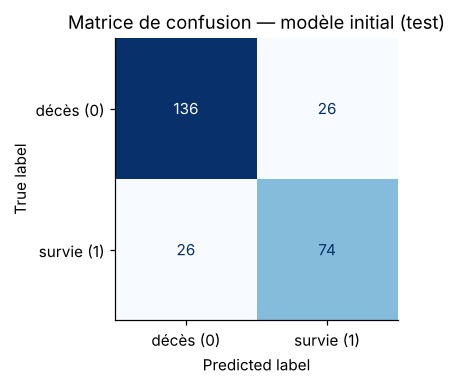

,train,test
accuracy,0.9542,0.8015
precision,0.9583,0.7400
recall,0.9200,0.7400
f1,0.9388,0.7400


Accuracy 'toujours décès' sur le test : 0.6183 | modèle initial : 0.8015 | gain : 18.3 points
Écart train - test (accuracy) : 15.3 points


In [ ]:
def metrics(model, Xs, ys):
    p = model.predict(Xs)
    return dict(accuracy=accuracy_score(ys, p), precision=precision_score(ys, p),
                recall=recall_score(ys, p), f1=f1_score(ys, p))

cm = confusion_matrix(y_test, pred_test)
tn, fp, fn, tp = cm.ravel()
print(f"Matrice de confusion (test) — VN={tn}  FP={fp}  FN={fn}  VP={tp}")
print(f"Spécificité (part des décès correctement prédits) = VN/(VN+FP) = {tn / (tn + fp):.4f}")
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["décès (0)", "survie (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matrice de confusion — modèle initial (test)")
plt.tight_layout(); plt.savefig("figures/q17_matrice_confusion.png"); plt.show()

m_init_test, m_init_train = metrics(model_init, X_test, y_test), metrics(model_init, X_train, y_train)
tab6 = pd.DataFrame({"train": m_init_train, "test": m_init_test}).round(4)
display(tab6)
base_test = 1 - y_test.mean()
print(f"Accuracy 'toujours décès' sur le test : {base_test:.4f} | modèle initial : {m_init_test['accuracy']:.4f} "
      f"| gain : {100 * (m_init_test['accuracy'] - base_test):.1f} points")
print(f"Écart train - test (accuracy) : {100 * (m_init_train['accuracy'] - m_init_test['accuracy']):.1f} points")

### Réponses — Partie 6

**Q17. Matrice de confusion (test, 262 passagers, dont 100 survivants et 162 décès).**
- **Vrais négatifs : 136** : décès correctement prédits.
- **Faux positifs : 26** : passagers annoncés survivants alors qu'ils sont morts.
- **Faux négatifs : 26** : passagers annoncés morts alors qu'ils ont survécu.
- **Vrais positifs : 74** : survivants correctement prédits.

**Q18. Métriques (test).**
- **Accuracy 0,8015** : 210 passagers sur 262 sont bien classés.
- **Précision 0,74** : quand le modèle annonce une survie, il a raison 74 fois sur 100.
- **Rappel 0,74** : sur 100 survivants réels, le modèle en retrouve 74.
- **F1 0,74** : moyenne harmonique de la précision et du rappel (ici égaux).

**Q19.** Le modèle qui prédit toujours « décès » obtient 61,8 % sur le test ; le modèle initial 80,2 %, soit **+18,3 points** : il apporte réellement de l'information (sexe, classe…) au-delà du simple taux de base. Ce gain est toutefois à relativiser par rapport à des modèles simples (Q35).

**Q20.** Accuracy **0,954 en entraînement contre 0,802 en test** : un écart de **15,3 points**. La précision passe de 0,958 à 0,74 et le rappel de 0,92 à 0,74. Le modèle initial fait donc du **surapprentissage** : avec 100 arbres de profondeur 6 et un pas de 0,3, il mémorise des particularités du jeu d'entraînement qui ne se généralisent pas.

**Q21.** Pas de réponse unique : cela dépend de l'usage. Si l'on imaginait utiliser le modèle pour **prioriser des secours**, l'erreur la plus coûteuse serait de **prédire à tort une survie** (faux positif) : une personne qui va mourir serait jugée hors de danger et passerait en dernier. Je privilégierais alors la **précision** de la classe « survie » et la spécificité (part des décès bien identifiés : 0,84 pour le modèle initial). Si au contraire on voulait ne laisser aucun survivant potentiel sans aide, ce serait le faux négatif qui coûterait le plus, et on suivrait le **rappel**. En l'absence d'usage précis, le F1 et la matrice de confusion complète sont les meilleurs résumés, et le seuil de 0,5 peut être déplacé selon le coût retenu.

## Partie 7 — Importance des variables

,importance_gain,permutation_(baisse_accuracy)
sex_female,0.5283,0.2019
pclass,0.1747,0.0959
sibsp,0.0712,0.0047
embarked_C,0.0472,0.0148
embarked_S,0.0407,-0.0001
fare,0.0375,0.0237
embarked_Q,0.0355,-0.0023
age,0.0345,0.0355
parch,0.0304,0.0042


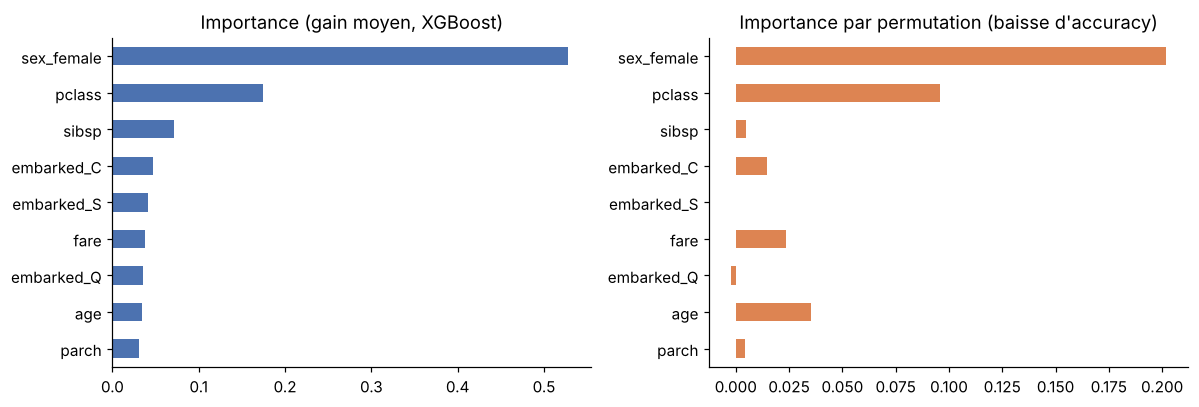

In [ ]:
imp = pd.Series(model_init.feature_importances_, index=X_train.columns).sort_values()
perm = permutation_importance(model_init, X_test, y_test, scoring="accuracy", n_repeats=30, random_state=SEED, n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=X_train.columns)
tab7 = pd.DataFrame({"importance_gain": imp, "permutation_(baisse_accuracy)": perm_s[imp.index]}).sort_values("importance_gain", ascending=False).round(4)
display(tab7)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
imp.plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("Importance (gain moyen, XGBoost)")
perm_s[imp.index].plot.barh(ax=axes[1], color="#DD8452"); axes[1].set_title("Importance par permutation (baisse d'accuracy)")
plt.tight_layout(); plt.savefig("figures/q22_importance_variables.png"); plt.show()

In [ ]:
# Q23 : variables corrélées entre elles
print("Corrélation de Spearman fare ~ pclass :", round(spearmanr(df["fare"], df["pclass"], nan_policy="omit")[0], 3))
print("Corrélation de Spearman sex_female ~ pclass :", round(spearmanr(X["sex_female"], X["pclass"])[0], 3))
print("\nSurvie selon le port d'embarquement (taux brut) :"); display(taux("embarked"))
print("Part de chaque port en 1ère classe (%) :")
display((100 * pd.crosstab(df["embarked"], df["pclass"], normalize="index")).round(1))
# Retirer une variable importante : l'information est-elle récupérée par les variables corrélées ?
for drop in [[], ["fare"], ["pclass"], ["pclass", "fare"], ["embarked_C", "embarked_Q", "embarked_S"], ["sex_female"]]:
    sc = cross_val_score(make_model(), X_train.drop(columns=drop), y_train, cv=cv, scoring="accuracy", n_jobs=2)
    print(f"CV accuracy sans {drop if drop else 'rien (modèle complet)'} : {sc.mean():.4f}")

Corrélation de Spearman fare ~ pclass : -0.709
Corrélation de Spearman sex_female ~ pclass : -0.125

Survie selon le port d'embarquement (taux brut) :


,taux_survie_%,effectif
embarked,,
C,55.6,270
Q,35.8,123
S,33.3,914


Part de chaque port en 1ère classe (%) :


pclass,1,2,3
embarked,,,
C,52.2,10.4,37.4
Q,2.4,5.7,91.9
S,19.4,26.5,54.2


CV accuracy sans rien (modèle complet) : 0.7832


CV accuracy sans ['fare'] : 0.7689
CV accuracy sans ['pclass'] : 0.7841


CV accuracy sans ['pclass', 'fare'] : 0.7574


CV accuracy sans ['embarked_C', 'embarked_Q', 'embarked_S'] : 0.7860


CV accuracy sans ['sex_female'] : 0.7020


### Réponses — Partie 7

**Q22. Importance des variables** (`figures/q22_importance_variables.png`).
- Par **gain** (importance native XGBoost), les trois premières sont `sex_female` (0,53), `pclass` (0,17) et `sibsp` (0,07).
- Par **permutation** (baisse d'accuracy sur le test quand on mélange la variable), le trio est `sex_female` (−0,202), `pclass` (−0,096) et `age` (−0,036), suivies de `fare` (−0,024).

Les deux mesures s'accordent sur le haut du classement : **sexe puis classe**, ce qui confirme H1 (pour le sexe) et H2, ainsi que la partie 5. L'âge compte moins, conformément à Q5 (effet surtout chez les enfants). Désaccord sur `sibsp` : 3e par gain mais quasi nul par permutation (−0,005) : le gain récompense les variables utilisées dans beaucoup de coupures même peu utiles, et la permutation sur seulement 262 passagers est bruitée (certaines valeurs sont ≈ 0 ou négatives).

**Q23. Importance ≠ causalité.**
- **Exemple `fare`** : le prix du billet est utile au modèle (sans lui, l'accuracy de validation croisée baisse de 1,4 point), mais payer plus cher ne sauvait personne : c'est un **substitut** de la classe (corrélation de Spearman fare/pclass = −0,71) et de l'emplacement des cabines. De même, le sexe est prédictif à cause de la règle d'évacuation « femmes et enfants d'abord », pas à cause d'un effet biologique.
- **Une variable peu importante n'est pas forcément sans lien avec la survie.** `embarked` : survie brute de 55,6 % à Cherbourg contre 33,3 % à Southampton, donc un lien net ; mais 52 % des embarqués de Cherbourg voyagent en 1re classe (19 % à Southampton), si bien que `pclass` et `fare` contiennent déjà cette information, d'où une importance faible (retirer `embarked` ne dégrade pas la validation croisée : 0,7860 contre 0,7832).
- Même phénomène avec les variables corrélées entre elles : retirer `pclass` seule ne change rien (0,7841) car `fare` la remplace ; retirer les deux fait perdre 2,6 points (0,7574). L'importance se répartit entre variables redondantes.

## Partie 8 — Hyperparamètres (validation croisée 5 plis sur l'ensemble d'entraînement uniquement)

### Réponses — Partie 8

**Q24. Rôle des hyperparamètres.**
- `n_estimators` : nombre d'arbres du boosting (nombre d'étapes de correction). Plus il est grand, plus le modèle est flexible et risque de surapprendre, surtout si le pas est grand.
- `max_depth` : profondeur maximale de chaque arbre ; elle contrôle la complexité de chaque arbre et le niveau d'interaction entre variables (une profondeur d permet des interactions jusqu'à d variables).
- `learning_rate` : facteur multiplicatif appliqué à la contribution de chaque arbre ; un pas petit rend l'apprentissage plus progressif et prudent.

Un **paramètre appris** est déterminé par l'algorithme à partir des données pendant l'entraînement (structure des arbres, seuils de coupure, valeurs des feuilles). Un **hyperparamètre** est fixé **avant** l'entraînement par l'utilisateur et contrôle le processus ou la complexité du modèle. On ne peut pas le choisir en minimisant l'erreur d'entraînement (on prendrait toujours le modèle le plus complexe) : on le choisit par validation.

*Protocole des expériences ci-dessous : validation croisée stratifiée à 5 plis sur le train, métrique accuracy, mêmes plis pour toutes les configurations ; les réglages non étudiés restent à la configuration initiale.*

,max_depth,cv_mean,cv_std,train_mean,écart (train-CV)
0,2,0.7927,0.0141,0.8596,0.0669
1,3,0.7966,0.0082,0.9002,0.1036
2,4,0.8032,0.0078,0.9308,0.1275
3,5,0.7918,0.0234,0.9513,0.1595
4,6,0.7832,0.0133,0.9596,0.1765
5,7,0.7822,0.0154,0.9635,0.1813
6,8,0.7803,0.0194,0.9680,0.1877


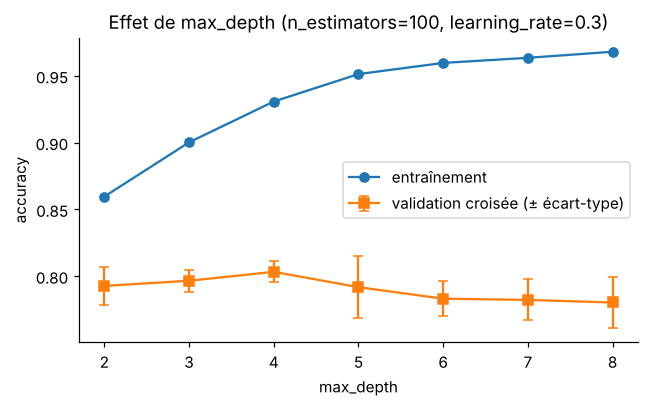

In [ ]:
def cv_run(**p):
    r = cross_validate(make_model(**p), X_train, y_train, cv=cv, scoring="accuracy",
                       return_train_score=True, n_jobs=2)
    return r

def cv_row(**p):
    r = cv_run(**p)
    return dict(cv_mean=r["test_score"].mean(), cv_std=r["test_score"].std(ddof=1), train_mean=r["train_score"].mean())

# Q25 : max_depth
rows = [dict(max_depth=d, **cv_row(max_depth=d)) for d in range(2, 9)]
t25 = pd.DataFrame(rows); t25["écart (train-CV)"] = t25.train_mean - t25.cv_mean
display(t25.round(4))
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(t25.max_depth, t25.train_mean, "o-", label="entraînement")
ax.errorbar(t25.max_depth, t25.cv_mean, yerr=t25.cv_std, fmt="s-", capsize=3, label="validation croisée (± écart-type)")
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.set_title("Effet de max_depth (n_estimators=100, learning_rate=0.3)")
ax.legend(); plt.tight_layout(); plt.savefig("figures/q25_max_depth.png"); plt.show()

**Q25. `max_depth` de 2 à 8** (`figures/q25_max_depth.png`). L'accuracy d'entraînement augmente de façon monotone, de 0,860 (profondeur 2) à 0,968 (profondeur 8) : des arbres plus profonds mémorisent davantage. L'accuracy de validation croisée progresse jusqu'à la profondeur 4 (**0,8032**), puis baisse légèrement (0,7803 à la profondeur 8). L'écart entre entraînement et validation passe ainsi de 6,7 à 18,8 points : au-delà de 4, le modèle surapprend. Précision : les variations de score de validation (≈ 2 points) restent comparables à l'écart-type entre plis (0,8 à 2,3 points), donc l'optimum est plat entre les profondeurs 2 et 5.

Configuration initiale (depth=6, lr=0.3) :


,n_estimators,cv_mean,cv_std,train_mean,écart (train-CV)
0,50,0.7956,0.0148,0.9403,0.1447
1,100,0.7832,0.0133,0.9596,0.1765
2,150,0.7832,0.0196,0.9668,0.1836
3,200,0.7765,0.0249,0.9702,0.1937
4,300,0.7736,0.0237,0.9721,0.1985
5,400,0.7698,0.0224,0.9725,0.2028
6,500,0.7688,0.0219,0.9725,0.2037


Série complémentaire (depth=3, lr=0.05) :


,n_estimators,cv_mean,cv_std,train_mean
0,50,0.8013,0.0183,0.8259
1,100,0.8052,0.0096,0.8403
2,150,0.8033,0.0124,0.8465
3,200,0.8004,0.0111,0.8536
4,300,0.8013,0.0095,0.8699
5,400,0.8023,0.0098,0.8785
6,500,0.8032,0.0085,0.8894


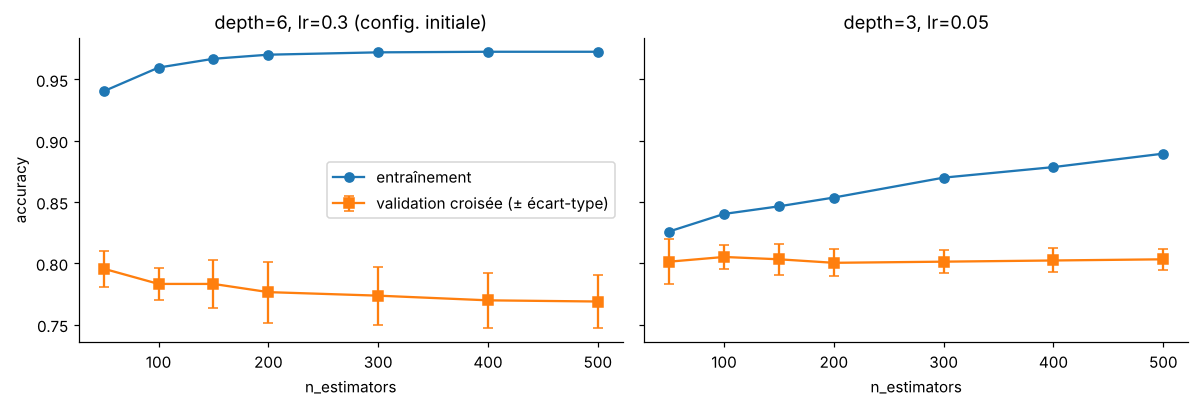

In [ ]:
# Q26 : n_estimators (autres réglages = configuration initiale) + série complémentaire (lr=0.05, depth=3)
ns = [50, 100, 150, 200, 300, 400, 500]
rows = [dict(n_estimators=n, **cv_row(n_estimators=n)) for n in ns]
t26 = pd.DataFrame(rows); t26["écart (train-CV)"] = t26.train_mean - t26.cv_mean
rows2 = [dict(n_estimators=n, **cv_row(n_estimators=n, learning_rate=0.05, max_depth=3)) for n in ns]
t26b = pd.DataFrame(rows2)
print("Configuration initiale (depth=6, lr=0.3) :"); display(t26.round(4))
print("Série complémentaire (depth=3, lr=0.05) :"); display(t26b.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, t, ttl in [(axes[0], t26, "depth=6, lr=0.3 (config. initiale)"), (axes[1], t26b, "depth=3, lr=0.05")]:
    ax.plot(t.n_estimators, t.train_mean, "o-", label="entraînement")
    ax.errorbar(t.n_estimators, t.cv_mean, yerr=t.cv_std, fmt="s-", capsize=3, label="validation croisée (± écart-type)")
    ax.set_xlabel("n_estimators"); ax.set_title(ttl)
axes[0].set_ylabel("accuracy"); axes[0].legend()
plt.tight_layout(); plt.savefig("figures/q26_n_estimators.png"); plt.show()

**Q26. `n_estimators` de 50 à 500** (`figures/q26_n_estimators.png`). Avec la configuration initiale (profondeur 6, pas 0,3), il n'y a pas d'amélioration au-delà de **50 arbres** : le score de validation est maximal à 50 arbres (0,7956), puis **décroît lentement** jusqu'à 0,7688 à 500 arbres, tandis que le score d'entraînement plafonne autour de 0,9725 : les arbres supplémentaires ne font que s'ajuster au bruit. Avec une série complémentaire plus prudente (profondeur 3, pas 0,05), la validation atteint 0,8052 à 100 arbres puis reste sur un **plateau** à 0,800–0,803 jusqu'à 500 arbres : à partir d'environ 100 arbres, ajouter des arbres n'améliore plus le score de validation, mais ne le dégrade pas non plus.

n_estimators,50,100,200,400,800,1200
learning_rate,,,,,,
0.01,0.7918,0.7956,0.8023,0.8109,0.8061,0.7985
0.05,0.8099,0.8080,0.8071,0.7956,0.7889,0.7832
0.10,0.8080,0.8023,0.7899,0.7851,0.7746,0.7717
0.30,0.7956,0.7832,0.7765,0.7698,0.7679,0.7650


Nombre d'arbres donnant le meilleur score CV pour chaque learning_rate : {0.01: 400, 0.05: 50, 0.1: 50, 0.3: 50}


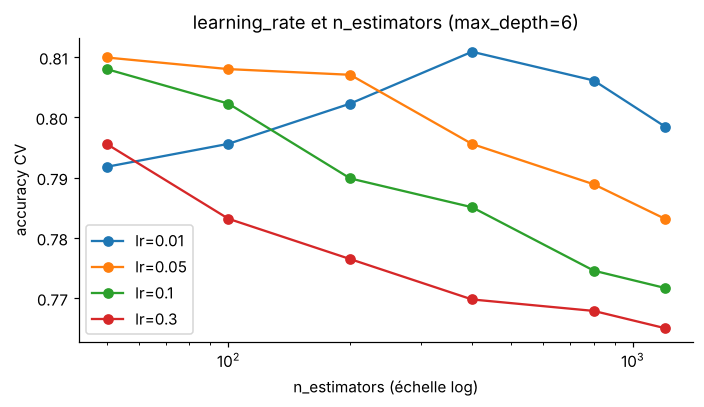

In [ ]:
# Q27 : learning_rate x n_estimators (max_depth=6 comme la configuration initiale)
lrs = [0.01, 0.05, 0.1, 0.3]
ns27 = [50, 100, 200, 400, 800, 1200]
rows = [dict(learning_rate=lr, n_estimators=n, cv_mean=cv_row(learning_rate=lr, n_estimators=n)["cv_mean"])
        for lr in lrs for n in ns27]
t27 = pd.DataFrame(rows).pivot(index="learning_rate", columns="n_estimators", values="cv_mean")
display(t27.round(4))
print("Nombre d'arbres donnant le meilleur score CV pour chaque learning_rate :", t27.idxmax(axis=1).to_dict())
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for lr in lrs:
    ax.plot(ns27, t27.loc[lr], "o-", label=f"lr={lr}")
ax.set_xscale("log"); ax.set_xlabel("n_estimators (échelle log)"); ax.set_ylabel("accuracy CV")
ax.set_title("learning_rate et n_estimators (max_depth=6)"); ax.legend()
plt.tight_layout(); plt.savefig("figures/q27_lr_vs_n_estimators.png"); plt.show()

**Q27. `learning_rate` et `n_estimators`.** Le modèle final est la somme des arbres, chacun multiplié par le `learning_rate`. Avec un pas petit, chaque arbre n'apporte qu'une petite correction : il en faut donc **davantage** pour atteindre la même capacité d'ajustement. En contrepartie, l'apprentissage est plus progressif et moins sensible au bruit (effet de régularisation). Vérification sur la validation croisée (profondeur 6, `figures/q27_lr_vs_n_estimators.png`) :
- pas 0,3 : meilleur à 50 arbres (0,7956), puis baisse jusqu'à 0,7650 à 1 200 arbres ;
- pas 0,1 : meilleur à 50 arbres (0,8080), puis 0,7717 à 1 200 ;
- pas 0,05 : meilleur à 50 arbres (0,8099), puis 0,7832 à 1 200 ;
- pas 0,01 : le score **monte** jusqu'à **400 arbres** (0,8109) avant de redescendre légèrement (0,7985 à 1 200).

Le nombre d'arbres optimal augmente donc bien quand le pas diminue (400 pour 0,01 contre 50 pour les pas ≥ 0,05). Réserve : pour 0,05, 0,1 et 0,3, l'optimum se trouve au bord inférieur de la grille testée (50 arbres), le vrai optimum pourrait être plus bas.

In [ ]:
# Q28 : Grid Search — 3 hyperparamètres x 4 valeurs
param_grid = {"max_depth": [2, 3, 4, 6],
              "n_estimators": [100, 200, 300, 500],
              "learning_rate": [0.01, 0.05, 0.1, 0.3]}
n_comb = int(np.prod([len(v) for v in param_grid.values()]))
gs = GridSearchCV(make_model(), param_grid, cv=cv, scoring="accuracy", return_train_score=True,
                  n_jobs=2, refit=False)
gs.fit(X_train, y_train)
print(f"Valeurs testées : {param_grid}")
print(f"Combinaisons : {n_comb} | plis : {cv.get_n_splits()} | modèles entraînés au total : {n_comb * cv.get_n_splits()}")

res = pd.DataFrame(gs.cv_results_)
res.columns = [c if not c.startswith("param_") else c[6:] for c in res.columns]
fold_cols = [f"split{k}_test_score" for k in range(cv.get_n_splits())]
res["cv_mean"] = res[fold_cols].mean(axis=1)
res["cv_std"] = res[fold_cols].std(axis=1, ddof=1)
res["train_mean"] = res["mean_train_score"]
res["cv_mean_r"] = res["cv_mean"].round(6)
# classement : meilleur score CV ; à égalité, le modèle le plus simple (moins profond, moins d'arbres)
res = res.sort_values(["cv_mean_r", "max_depth", "n_estimators"], ascending=[False, True, True]).reset_index(drop=True)
cols = ["max_depth", "n_estimators", "learning_rate", "cv_mean", "cv_std", "train_mean"]

Valeurs testées : {'max_depth': [2, 3, 4, 6], 'n_estimators': [100, 200, 300, 500], 'learning_rate': [0.01, 0.05, 0.1, 0.3]}
Combinaisons : 64 | plis : 5 | modèles entraînés au total : 320


**Q28. Recherche combinée (Grid Search).** Valeurs testées : `max_depth` ∈ {2, 3, 4, 6}, `n_estimators` ∈ {100, 200, 300, 500}, `learning_rate` ∈ {0,01 ; 0,05 ; 0,1 ; 0,3}. Cela fait 4 × 4 × 4 = **64 combinaisons**, chacune évaluée sur 5 plis, soit **320 modèles entraînés** (aucun réentraînement final dans la recherche ; le modèle optimisé est entraîné une fois en partie 9).

,max_depth,n_estimators,learning_rate,cv_mean,cv_std,train_mean
rang,,,,,,
1,4,300,0.01,0.8109,0.0125,0.8393
2,6,500,0.01,0.8109,0.0169,0.8880
3,4,200,0.01,0.8099,0.0134,0.8286
4,4,200,0.05,0.8099,0.0067,0.8770
5,6,300,0.01,0.8090,0.0114,0.8696
6,4,100,0.10,0.8080,0.0061,0.8794
7,6,100,0.05,0.8080,0.0144,0.8892
8,4,100,0.05,0.8071,0.0054,0.8510
9,6,200,0.05,0.8071,0.0101,0.9191


Meilleure combinaison : {'max_depth': 4, 'n_estimators': 300, 'learning_rate': 0.01} | CV = 0.8109 ± 0.0125
Écart entre les rangs 1 et 2 : 0.00 pt | rang 1 et 5 : 0.19 pt | écart-type entre plis du rang 1 : 1.25 pt
Combinaisons dont le score est à moins d'1 écart-type du meilleur : 31 sur 64
Score CV minimal / médian / maximal sur la grille : 0.7688 / 0.7975 / 0.8109


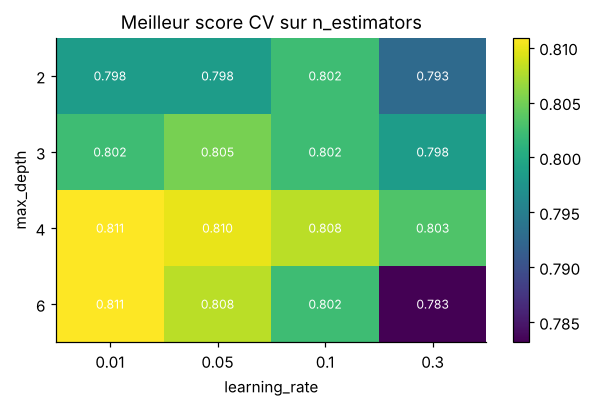

In [ ]:
# Q29
top = res[cols].head(10).copy(); top.index = top.index + 1; top.index.name = "rang"
display(top.round(4))
best = res.iloc[0]
best_params = dict(max_depth=int(best.max_depth), n_estimators=int(best.n_estimators), learning_rate=float(best.learning_rate))
print("Meilleure combinaison :", best_params, f"| CV = {best.cv_mean:.4f} ± {best.cv_std:.4f}")
print(f"Écart entre les rangs 1 et 2 : {100 * (res.cv_mean[0] - res.cv_mean[1]):.2f} pt | rang 1 et 5 : {100 * (res.cv_mean[0] - res.cv_mean[4]):.2f} pt "
      f"| écart-type entre plis du rang 1 : {100 * best.cv_std:.2f} pt")
within = res[res.cv_mean >= best.cv_mean - best.cv_std]
print(f"Combinaisons dont le score est à moins d'1 écart-type du meilleur : {len(within)} sur {n_comb}")
print(f"Score CV minimal / médian / maximal sur la grille : {res.cv_mean.min():.4f} / {res.cv_mean.median():.4f} / {res.cv_mean.max():.4f}")

pv = res.groupby(["max_depth", "learning_rate"])["cv_mean"].max().unstack()
fig, ax = plt.subplots(figsize=(5.6, 3.8))
im = ax.imshow(pv.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(pv.columns)), pv.columns); ax.set_yticks(range(len(pv.index)), pv.index)
ax.set_xlabel("learning_rate"); ax.set_ylabel("max_depth"); ax.set_title("Meilleur score CV sur n_estimators")
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        ax.text(j, i, f"{pv.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig("figures/q29_grille.png"); plt.show()

**Q29. Meilleure combinaison.** `max_depth=4`, `n_estimators=300`, `learning_rate=0.01`, avec un score de validation croisée de **0,8109 ± 0,0125** (entraînement 0,839). Une autre combinaison (profondeur 6, 500 arbres, pas 0,01) obtient le même score à quatre décimales mais surapprend davantage (entraînement 0,888) ; à égalité, j'ai choisi la plus simple.

Les meilleures combinaisons **ne sont pas séparées** : les rangs 1 à 5 sont à 0,19 point d'écart, alors que l'écart-type entre plis du meilleur est de 1,25 point ; **31 combinaisons sur 64** sont à moins d'un écart-type du meilleur. Sur toute la grille, le score va de 0,7688 à 0,8109 (médiane 0,7975) : l'écart entre bons et mauvais réglages (≈ 4 points) est visible, mais l'ordre précis au sein du groupe de tête est affaire de hasard. Tendances : les profondeurs faibles (3–4) et les pas petits dominent le haut du classement, les pires combinaisons associent grande profondeur, pas élevé et nombreux arbres. Enfin, choisir le maximum de 64 scores calculés sur les mêmes plis rend le score retenu légèrement **optimiste**.

## Partie 9 — Comparaison avant / après fine-tuning

In [ ]:
# Le test est utilisé ICI, une seule fois, pour le modèle optimisé
model_best = make_model(**best_params).fit(X_train, y_train)
m_best_test, m_best_train = metrics(model_best, X_test, y_test), metrics(model_best, X_train, y_train)

r_init = cv_run(**CONFIG_INIT)
init_cv, init_std = r_init["test_score"].mean(), r_init["test_score"].std(ddof=1)
comp = pd.DataFrame({
    "Modèle initial": {"hyperparamètres": str(CONFIG_INIT), "CV accuracy (moy. ± écart-type)": f"{init_cv:.4f} ± {init_std:.4f}",
                       "accuracy test": m_init_test["accuracy"], "précision test": m_init_test["precision"],
                       "rappel test": m_init_test["recall"], "F1 test": m_init_test["f1"],
                       "spécificité test": tn / (tn + fp),
                       "accuracy train": m_init_train["accuracy"], "écart train - test": m_init_train["accuracy"] - m_init_test["accuracy"]},
    "Modèle optimisé": {"hyperparamètres": str(best_params), "CV accuracy (moy. ± écart-type)": f"{best.cv_mean:.4f} ± {best.cv_std:.4f}",
                        "accuracy test": m_best_test["accuracy"], "précision test": m_best_test["precision"],
                        "rappel test": m_best_test["recall"], "F1 test": m_best_test["f1"],
                        "spécificité test": confusion_matrix(y_test, model_best.predict(X_test)).ravel()[0] / (y_test == 0).sum(),
                        "accuracy train": m_best_train["accuracy"], "écart train - test": m_best_train["accuracy"] - m_best_test["accuracy"]}})
display(comp.map(lambda v: round(v, 4) if isinstance(v, float) else v))
cm_b = confusion_matrix(y_test, model_best.predict(X_test)); print("Matrice de confusion optimisée (VN, FP, FN, VP) :", cm_b.ravel())

,Modèle initial,Modèle optimisé
hyperparamètres,"{'n_estimators': 100, 'max_depth': 6, 'learnin...","{'max_depth': 4, 'n_estimators': 300, 'learnin..."
CV accuracy (moy. ± écart-type),0.7832 ± 0.0133,0.8109 ± 0.0125
accuracy test,0.8015,0.8321
précision test,0.74,0.8415
rappel test,0.74,0.69
F1 test,0.74,0.7582
spécificité test,0.8395,0.9198
accuracy train,0.9542,0.8348
écart train - test,0.1526,0.0027


Matrice de confusion optimisée (VN, FP, FN, VP) : [149  13  31  69]


In [ ]:
# Q31 : l'écart est-il significatif ?
n_test = len(y_test)
p_i, p_b = model_init.predict(X_test), model_best.predict(X_test)
ok_i, ok_b = (p_i == y_test.values), (p_b == y_test.values)
print(f"Accuracy test : initial {ok_i.mean():.4f} | optimisé {ok_b.mean():.4f} | différence {100 * (ok_b.mean() - ok_i.mean()):+.2f} points "
      f"= {int(ok_b.sum() - ok_i.sum()):+d} passagers sur {n_test}")
for nom, ok in [("initial", ok_i), ("optimisé", ok_b)]:
    ci = binomtest(int(ok.sum()), n_test).proportion_ci(method="wilson")
    print(f"IC 95% (Wilson) de l'accuracy test {nom} : [{ci.low:.3f} ; {ci.high:.3f}]  (largeur {100 * (ci.high - ci.low):.1f} points)")
b01, b10 = int((ok_i & ~ok_b).sum()), int((~ok_i & ok_b).sum())
print(f"Désaccords : initial juste/optimisé faux = {b01} | initial faux/optimisé juste = {b10}")
print("Test exact de McNemar : p =", round(binomtest(b10, b01 + b10, 0.5).pvalue, 4) if b01 + b10 > 0 else "n/a")
rng = np.random.default_rng(SEED)
diffs = [(ok_b[i].mean() - ok_i[i].mean()) for i in (rng.integers(0, n_test, n_test) for _ in range(5000))]
print(f"Bootstrap (5000 rééchantillonnages) — différence d'accuracy : IC 95% = [{100 * np.percentile(diffs, 2.5):+.2f} ; {100 * np.percentile(diffs, 97.5):+.2f}] points")
# Différence par pli de CV (mêmes plis pour les deux modèles)
fold_best = best[fold_cols].astype(float).values
fold_diff = fold_best - r_init["test_score"]
print(f"Validation croisée — différence par pli (optimisé - initial) : {np.round(100 * fold_diff, 2)} points | moyenne {100 * fold_diff.mean():+.2f} "
      f"| écart-type {100 * fold_diff.std(ddof=1):.2f} | écart-type des plis du modèle initial {100 * init_std:.2f}")
print(f"Précision de l'estimation sur {n_test} passagers : 1 passager = {100 / n_test:.2f} point d'accuracy ; erreur-type ≈ {100 * np.sqrt(ok_b.mean() * (1 - ok_b.mean()) / n_test):.1f} points")

Accuracy test : initial 0.8015 | optimisé 0.8321 | différence +3.05 points = +8 passagers sur 262
IC 95% (Wilson) de l'accuracy test initial : [0.749 ; 0.845]  (largeur 9.6 points)
IC 95% (Wilson) de l'accuracy test optimisé : [0.782 ; 0.872]  (largeur 9.0 points)
Désaccords : initial juste/optimisé faux = 8 | initial faux/optimisé juste = 16
Test exact de McNemar : p = 0.1516
Bootstrap (5000 rééchantillonnages) — différence d'accuracy : IC 95% = [-0.38 ; +6.87] points
Validation croisée — différence par pli (optimisé - initial) : [2.86 0.95 3.83 2.39 3.83] points | moyenne +2.77 | écart-type 1.19 | écart-type des plis du modèle initial 1.33
Précision de l'estimation sur 262 passagers : 1 passager = 0.38 point d'accuracy ; erreur-type ≈ 2.3 points


### Réponses — Partie 9

**Q30. Comparaison avant / après fine-tuning** (test utilisé une seule fois pour le modèle optimisé).

| | Modèle initial | Modèle optimisé |
|---|---|---|
| Hyperparamètres | `n_estimators=100`, `max_depth=6`, `learning_rate=0.3` | `n_estimators=300`, `max_depth=4`, `learning_rate=0.01` |
| Score de validation croisée (moy. ± éc.-type) | 0,7832 ± 0,0133 | 0,8109 ± 0,0125 |
| Accuracy (test) | 0,8015 | **0,8321** |
| Précision (test) | 0,7400 | **0,8415** |
| Rappel (test) | **0,7400** | 0,6900 |
| F1 (test) | 0,7400 | **0,7582** |
| Spécificité (test) | 0,8395 | **0,9198** |
| Accuracy (train) | 0,9542 | 0,8348 |
| Écart train − test | 0,1526 | 0,0027 |

Matrice de confusion du modèle optimisé (VN / FP / FN / VP) : 149 / 13 / 31 / 69.

**Q31. L'amélioration est-elle significative ?** Elle est **faible à modérée** : +3,05 points d'accuracy sur le test, soit 8 passagers de plus bien classés sur 262 (16 gagnés, 8 perdus). Elle est de nature particulière : la précision monte (0,74 → 0,84, faux positifs 26 → 13) mais le rappel baisse (0,74 → 0,69, faux négatifs 26 → 31).
- En validation croisée, le gain moyen est de +2,8 points, positif sur les 5 plis (écart-type des différences : 1,2 point, du même ordre que celui des plis, 1,3 point), mais le réglage a été choisi sur ces mêmes plis, donc ce gain est optimiste.
- Sur le test, il **n'est pas démontré** : le test de McNemar exact donne p = 0,15, et l'intervalle bootstrap à 95 % de la différence est [−0,4 ; +6,9] points, qui contient 0.
- Pourquoi un petit test est peu fiable : avec 262 passagers, un passager vaut 0,38 point d'accuracy, l'erreur-type est d'environ 2,3 points et l'intervalle de confiance à 95 % de chaque accuracy mesure environ 9 à 10 points de large ([0,749 ; 0,845] et [0,782 ; 0,872]). Un écart de 3 points ne se détache donc pas du bruit d'échantillonnage. Le score de test du modèle optimisé (0,832) est d'ailleurs supérieur à son score de validation croisée (0,811), ce qui reste dans le bruit.

**Conclusion Q31 :** amélioration probable mais modeste, cohérente entre validation croisée et test et expliquée par une réduction du surapprentissage, sans qu'on puisse affirmer qu'elle soit significative.

**Q32. Surapprentissage.** L'écart train − test passe de **15,3 points** (0,954 contre 0,802) à **0,3 point** (0,835 contre 0,832) : le surapprentissage a **nettement diminué**. Cet écart quasi nul est en partie dû à un test favorable ; une mesure plus stable est l'écart entraînement − validation croisée : 17,6 points avant (0,959 − 0,783) contre 2,8 points après (0,839 − 0,811). Le modèle optimisé est plus simple (profondeur 4, pas très petit) et son score d'entraînement est bien plus bas, mais il généralise au moins aussi bien.

## Partie 10 — Interprétation et limites

In [ ]:
# Q35 : XGBoost est-il nécessairement meilleur qu'un modèle simple ? (comparaison en CV répétée, sur le TRAIN uniquement)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=123)   # plis différents de ceux du Grid Search
modeles = {
    "Règle 'femme => survit'": None,
    "Régression logistique": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)),
    "XGBoost initial": make_model(**CONFIG_INIT),
    "XGBoost optimisé": make_model(**best_params)}
rows = []
for nom, m in modeles.items():
    if m is None:
        # règle fixe sans apprentissage : même découpage pour comparer
        sc = np.array([accuracy_score(y_train.iloc[v], X_train["sex_female"].iloc[v]) for _, v in rcv.split(X_train, y_train)])
    else:
        sc = cross_val_score(m, X_train, y_train, cv=rcv, scoring="accuracy", n_jobs=2)
    rows.append((nom, sc.mean(), sc.std(ddof=1)))
t35 = pd.DataFrame(rows, columns=["modèle", "accuracy CV (5x5 plis)", "écart-type"]).round(4)
display(t35)

,modèle,accuracy CV (5x5 plis),écart-type
0,Règle 'femme => survit',0.7746,0.0230
1,Régression logistique,0.7834,0.0266
2,XGBoost initial,0.7788,0.0194
3,XGBoost optimisé,0.8038,0.0218


### Réponses — Partie 10

**Q33. Ce que l'on retient des trois hyperparamètres.**
- **`max_depth`** : plus il augmente, plus le score d'entraînement monte et plus l'écart avec la validation grandit ; l'optimum est à 3–4. Risque de surapprentissage : profondeurs ≥ 5–6. Effet limitant : profondeurs faibles.
- **`n_estimators`** : n'améliore plus la validation après ~50–100 arbres quand le pas est élevé, et dégrade lentement le modèle (0,7956 → 0,7688 de 50 à 500 arbres avec pas 0,3 et profondeur 6). Risque : beaucoup d'arbres avec un grand pas.
- **`learning_rate`** : un pas petit (0,01) demande beaucoup plus d'arbres (≈ 400) mais donne les meilleurs scores et le modèle le moins surappris ; un pas de 0,3 surapprend dès 50 arbres.
- Réglage le plus sûr : arbres peu profonds, petit pas, nombre d'arbres choisi par validation. D'autres leviers de régularisation n'ont pas été explorés (`subsample`, `colsample_bytree`, `min_child_weight`, `reg_lambda`, `gamma`, arrêt précoce).

**Q34. Limites de l'étude.**
- **Taille** : 1 309 passagers, 262 en test ; l'incertitude (≈ ±4,5 points à 95 %) est supérieure au gain mesuré, et un seul découpage (graine 42) a été utilisé.
- **Validation** : l'écart-type entre plis (1–2 points) est du même ordre que les différences entre bons réglages ; la sélection du meilleur de 64 combinaisons sur les mêmes plis biaise le score vers le haut.
- **Valeurs manquantes** : 20 % d'âges manquants, dont l'absence est informative ; `cabin`, `body` et `boat` inutilisables.
- **Variables écartées** : `name` (titre), `cabin` (pont), `ticket` (familles voyageant ensemble) pourraient apporter du signal ; aucune variable construite (taille de famille, titre) n'a été testée.
- **Données historiques** : 1912, normes sociales particulières (« femmes et enfants d'abord ») qui ne se transposent pas ; seuls les passagers sont décrits (pas l'équipage) ; certaines données sont incomplètes (23 survivants sans canot renseigné).
- **Méthode de recherche** : grille grossière (4 valeurs par hyperparamètre), 3 hyperparamètres seulement, accuracy comme unique critère ; une recherche aléatoire ou bayésienne, ou la log-loss / l'AUC, pourraient conduire à d'autres réglages.

**Q35. XGBoost est-il nécessairement plus adapté qu'un modèle simple ?** **Non.** Comparaison en validation croisée répétée (5 × 5 plis, train uniquement) :

| Modèle | Accuracy CV | Écart-type |
|---|---|---|
| Règle « femme ⇒ survit » (sans apprentissage) | 0,7746 | 0,0230 |
| Régression logistique | 0,7834 | 0,0266 |
| XGBoost initial | 0,7788 | 0,0194 |
| XGBoost optimisé | 0,8038 | 0,0218 |

Une règle à une variable et une régression logistique font pratiquement aussi bien que XGBoost non réglé ; le modèle optimisé gagne environ 2 points, à la limite d'un écart-type, et ce chiffre est favorable car ses hyperparamètres ont été choisis sur les mêmes données d'entraînement. XGBoost est surtout intéressant quand il y a beaucoup de variables, des interactions complexes et des valeurs manquantes ; ici, deux variables dominent. Pour **vérifier** : comparer les modèles avec une **validation croisée imbriquée** (réglage dans la boucle interne, évaluation dans la boucle externe), avec des tests appariés sur les mêmes plis, avec plusieurs métriques (AUC, log-loss, calibration) et avec des baselines simples plus fortes (régression logistique avec interaction sexe × classe, arbre peu profond), idéalement sur davantage de données ; il faut aussi tenir compte de l'interprétabilité et du coût de maintenance.

---

## Conclusion

- **Performance obtenue.** Modèle initial : 80,2 % d'accuracy sur le test (78,3 % en validation croisée). Modèle optimisé : 83,2 % sur le test (81,1 % en validation croisée), contre 61,8 % pour la réponse triviale « décès » et environ 77–78 % pour une règle sur le sexe seul.
- **Apport du fine-tuning.** Il réduit fortement le surapprentissage (écart train − test de 15,3 à 0,3 point ; écart train − validation de 17,6 à 2,8 points) et améliore la précision (0,74 → 0,84) au prix d'un rappel un peu plus bas (0,74 → 0,69). Le gain d'accuracy (+3 points) est cohérent entre validation croisée et test mais n'est pas statistiquement établi sur le test (McNemar p = 0,15).
- **Ce qui prédit la survie.** Sexe et classe dominent ; l'âge joue surtout pour les enfants ; plusieurs importances reflètent des corrélations (tarif, port) plutôt que des causes. `boat` et `body` sont des fuites de données et ont été exclues, car elles font passer l'accuracy de 0,78 à 0,97 de façon artificielle.
- **Limites.** Petit échantillon, un seul découpage, sélection sur 64 combinaisons, données historiques ; sur ce problème, un modèle simple fait presque aussi bien.